In [1]:
import pickle
from pathlib import Path

with open("/home/ubuntu/eGFR25_output/recovery_full.pkl", "rb") as f:
    ckpt = pickle.load(f)

# 변수 복원
for k, v in ckpt.items():
    globals()[k] = v

print(f"✅ Loaded {len(ckpt)} items:")
for k in ckpt:
    print(f"  - {k}")

print(f"\nres_A_test keys: {list(res_A_test.keys())}")
print(f"res_B_ext keys:  {list(res_B_ext.keys())}")

✅ Loaded 16 items:
  - res_A_test
  - res_A_ext
  - res_B_test
  - res_B_ext
  - y_test_A
  - y_ext_A
  - y_test
  - y_ext
  - df_test_A_imp
  - df_ext_A_imp
  - df_test_B_imp
  - df_ext_B_imp
  - pred_test_A
  - pred_ext_A
  - pred_test_B
  - pred_ext_B

res_A_test keys: ['summary', 'pairwise_discrimination', 'nri', 'cindex', 'pairwise_cindex']
res_B_ext keys:  ['summary', 'pairwise_discrimination', 'nri', 'cindex', 'pairwise_cindex']


In [2]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
from pathlib import Path

OUTDIR = Path("/home/ubuntu/eGFR25_output")
OUTDIR.mkdir(exist_ok=True)

print("✅ Libraries loaded")

✅ Libraries loaded


=== Scenario A ===


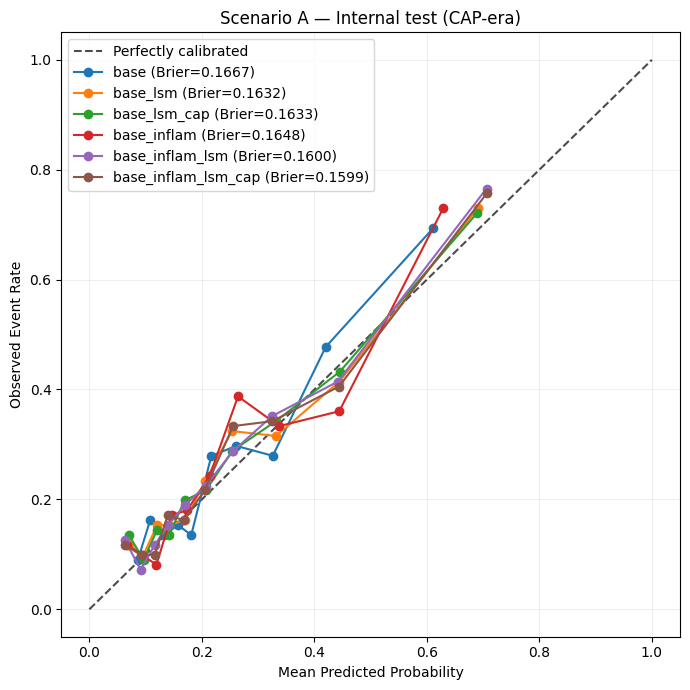

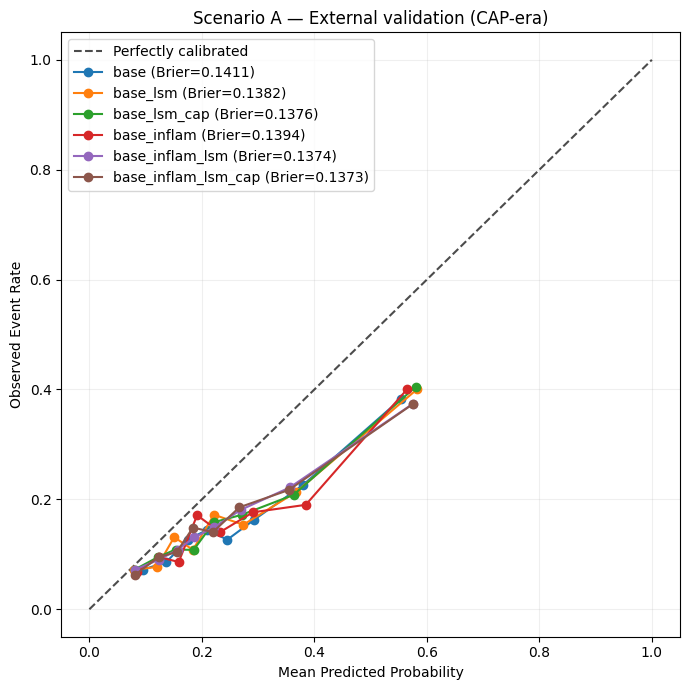


=== Scenario B ===


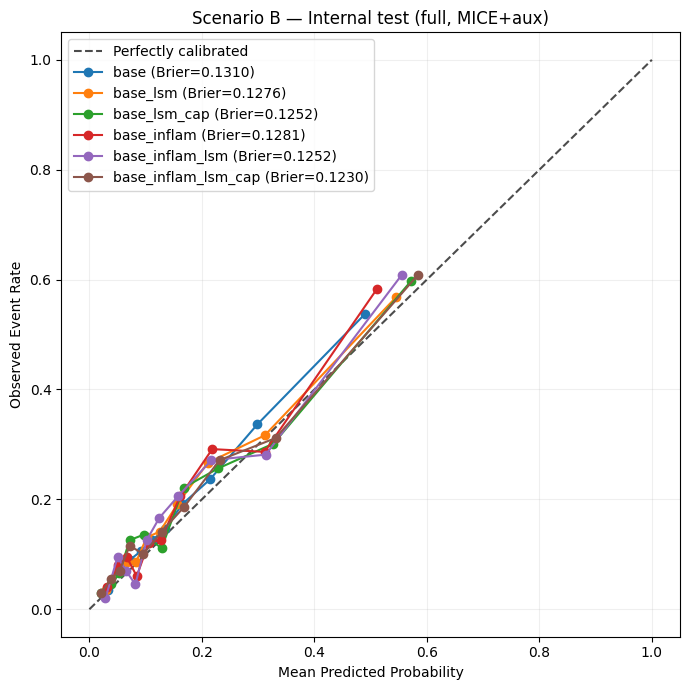

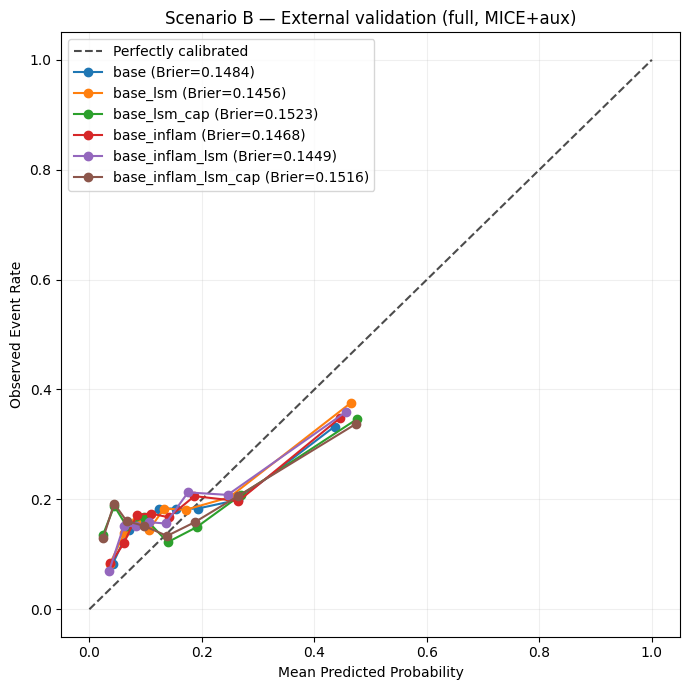

In [3]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

def calib_plot(pred_dict,y_true,title,n_bins=10,strategy="quantile"):
    cols=[m for m in pred_dict if "GGT" not in m.upper()]
    fig,ax=plt.subplots(figsize=(7,7))
    ax.plot([0,1],[0,1],"k--",label="Perfectly calibrated",alpha=0.7)
    for m in cols:
        pt,pp=calibration_curve(y_true,pred_dict[m],n_bins=n_bins,strategy=strategy)
        br=brier_score_loss(y_true,pred_dict[m])
        ax.plot(pp,pt,marker="o",linewidth=2.5 if "LSM" in m else 1.5,
                label=f"{m} (Brier={br:.4f})")
    ax.set_xlabel("Mean Predicted Probability")
    ax.set_ylabel("Observed Event Rate")
    ax.set_title(title); ax.legend(loc="upper left")
    ax.grid(True,alpha=0.2); plt.tight_layout(); plt.show()

print("=== Scenario A ===")
calib_plot(pred_test_A,y_test_A,"Scenario A — Internal test (CAP-era)")
calib_plot(pred_ext_A, y_ext_A, "Scenario A — External validation (CAP-era)",n_bins=8)

print("\n=== Scenario B ===")
calib_plot(pred_test_B,y_test,"Scenario B — Internal test (full, MICE+aux)")
calib_plot(pred_ext_B, y_ext, "Scenario B — External validation (full, MICE+aux)",n_bins=8)

=== Scenario A ===


/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/tmp/ipykernel_103482/3406718860.py:92: UserWarning:

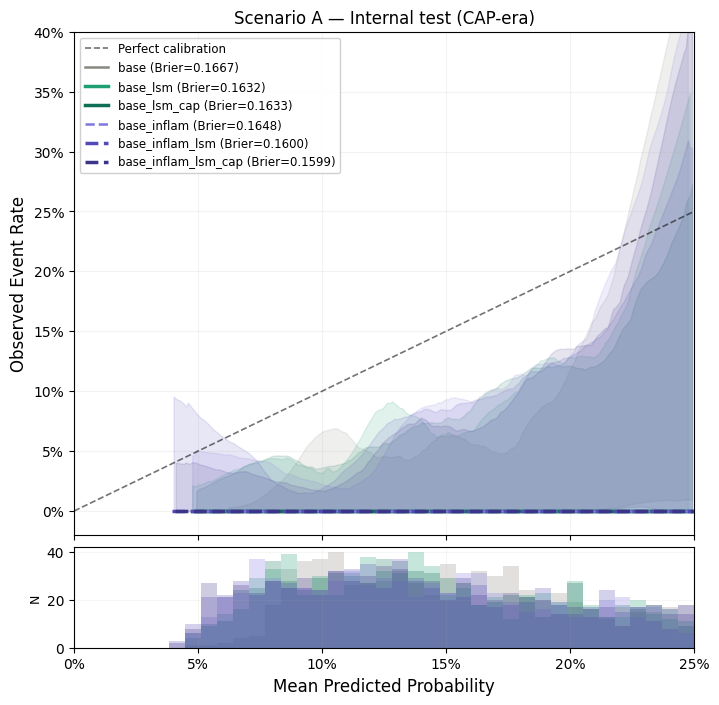

/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/tmp/ipykernel_103482/3406718860.py:92: UserWarning:

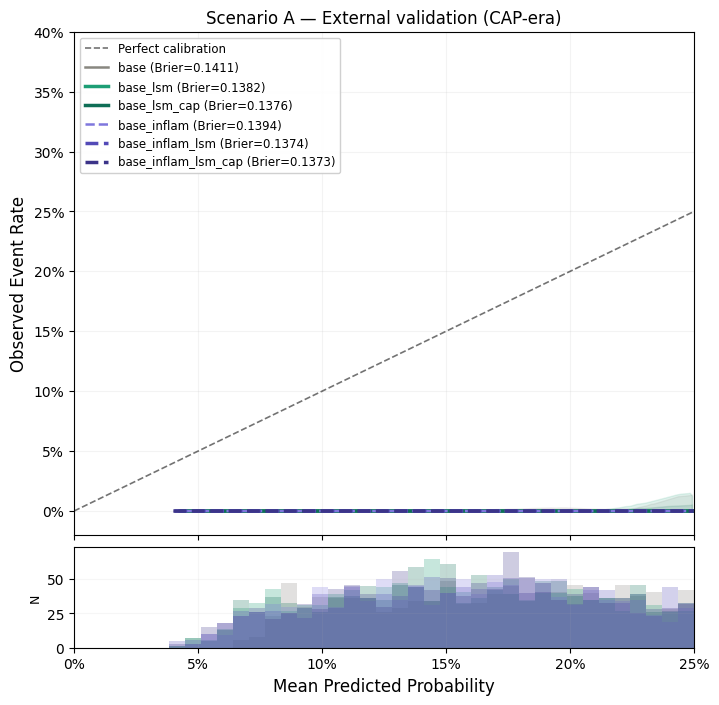


=== Scenario B ===


/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/tmp/ipykernel_103482/3406718860.py:92: UserWarning:

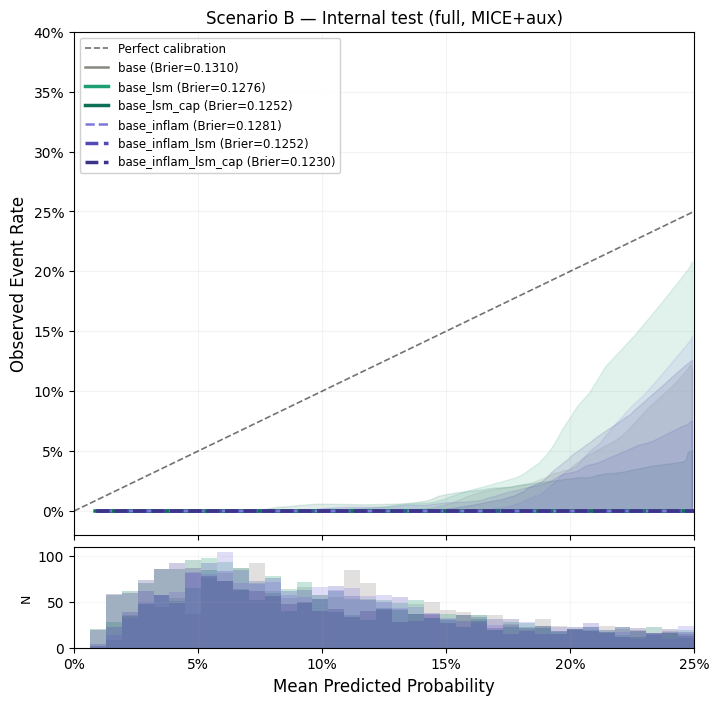

/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/tmp/ipykernel_103482/3406718860.py:92: UserWarning:

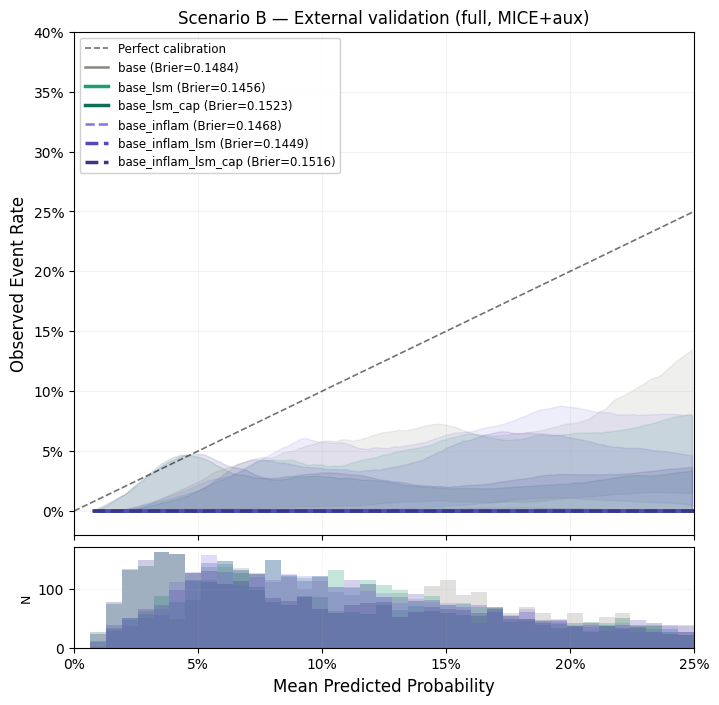

In [4]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
from sklearn.metrics import brier_score_loss
from statsmodels.nonparametric.smoothers_lowess import lowess

_STYLE_MAP = {
    "base":                dict(ls="-",  lw=1.8, color="#888780"),
    "base_lsm":            dict(ls="-",  lw=2.5, color="#1D9E75"),
    "base_lsm_cap":        dict(ls="-",  lw=2.5, color="#0F6E56"),
    "base_inflam":         dict(ls="--", lw=1.8, color="#7F77DD"),
    "base_inflam_lsm":     dict(ls="--", lw=2.5, color="#534AB7"),
    "base_inflam_lsm_cap": dict(ls="--", lw=2.5, color="#3C3489"),
}

def calib_plot(pred_dict, y_true, title,
               frac=0.30, n_bootstrap=500,
               xlim=(0.0, 0.25), ylim=(-0.02, 0.40),
               save_path=None):

    y_arr  = np.asarray(y_true, dtype=float)
    x_grid = np.linspace(xlim[0] + 0.001, xlim[1], 300)
    rng    = np.random.default_rng(42)

    fig, (ax_main, ax_hist) = plt.subplots(
        2, 1, figsize=(8, 8),
        gridspec_kw={"height_ratios": [5, 1], "hspace": 0.04},
        sharex=True,
    )

    x_ref = np.linspace(*xlim, 300)
    ax_main.plot(x_ref, x_ref, "k--", lw=1.2, alpha=0.55, label="Perfect calibration")

    for m, p_raw in pred_dict.items():
        if "GGT" in m.upper():
            continue
        p   = np.clip(np.asarray(p_raw, dtype=float), 1e-7, 1 - 1e-7)
        sty = _STYLE_MAP.get(m, dict(ls="-", lw=2, color="steelblue"))

        mask     = (p >= xlim[0]) & (p <= xlim[1])
        p_m, y_m = p[mask], y_arr[mask]
        if len(p_m) < 20:
            print(f"  [WARN] {m}: {len(p_m)}개 포인트 — LOWESS 생략")
            continue

        sort_idx   = np.argsort(p_m)
        smooth_pts = lowess(y_m[sort_idx], p_m[sort_idx],
                            frac=frac, it=3, return_sorted=True)
        smooth_pts[:, 1] = np.clip(smooth_pts[:, 1], 0, 1)

        # Bootstrap CI
        boot_curves = np.empty((n_bootstrap, len(x_grid)))
        for b in range(n_bootstrap):
            idx_b    = rng.integers(0, len(p_m), len(p_m))
            p_b, y_b = p_m[idx_b], y_m[idx_b]
            sort_b   = np.argsort(p_b)
            sm_b     = lowess(y_b[sort_b], p_b[sort_b],
                              frac=frac, it=1, return_sorted=True)
            sm_b[:, 1] = np.clip(sm_b[:, 1], 0, 1)
            boot_curves[b] = np.interp(x_grid, sm_b[:, 0], sm_b[:, 1],
                                        left=np.nan, right=np.nan)

        lower = np.nanpercentile(boot_curves, 2.5, axis=0)
        upper = np.nanpercentile(boot_curves, 97.5, axis=0)

        br = brier_score_loss(y_arr, p)
        ax_main.plot(smooth_pts[:, 0], smooth_pts[:, 1],
                     label=f"{m} (Brier={br:.4f})", **sty)
        ax_main.fill_between(x_grid, lower, upper,
                              alpha=0.13, color=sty["color"])

    ax_main.set_ylabel("Observed Event Rate", fontsize=12)
    ax_main.set_ylim(ylim)
    ax_main.set_xlim(xlim)
    ax_main.legend(loc="upper left", fontsize=8.5, framealpha=0.92)
    ax_main.set_title(title, fontsize=12)
    ax_main.grid(True, alpha=0.15)
    ax_main.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
    ax_main.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))

    ax_hist.set_ylabel("N", fontsize=9)
    ax_hist.set_xlabel("Mean Predicted Probability", fontsize=12)
    ax_hist.grid(True, alpha=0.10)
    for m, p_raw in pred_dict.items():
        if "GGT" in m.upper():
            continue
        p   = np.clip(np.asarray(p_raw, dtype=float), 1e-7, 1 - 1e-7)
        clr = _STYLE_MAP.get(m, {}).get("color", "steelblue")
        ax_hist.hist(p, bins=np.linspace(xlim[0], xlim[1], 40),
                     alpha=0.25, color=clr)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"[SAVE] {save_path}")
    plt.show()
    plt.close()


# ── 실행 ──────────────────────────────────────────────────────────────────────
print("=== Scenario A ===")
calib_plot(pred_test_A, y_test_A, "Scenario A — Internal test (CAP-era)")
calib_plot(pred_ext_A,  y_ext_A,  "Scenario A — External validation (CAP-era)")

print("\n=== Scenario B ===")
calib_plot(pred_test_B, y_test, "Scenario B — Internal test (full, MICE+aux)")
calib_plot(pred_ext_B,  y_ext,  "Scenario B — External validation (full, MICE+aux)")

In [6]:
##

In [7]:
# shap models_a, models_b loading
import sys
sys.path.insert(0, "/home/ubuntu/eGFR25_output/models/src")
from tabpfn.model_loading import load_fitted_tabpfn_model
import joblib
from sklearn.pipeline import Pipeline

PKG_DIR = Path("/home/ubuntu/eGFR25_output/models")



In [9]:
# 어떤 변수들이 살아있는지 확인
[k for k in dir() if not k.startswith('_') and ('df_' in k or 'imp_' in k)]

['df_ext_A_imp', 'df_ext_B_imp', 'df_test_A_imp', 'df_test_B_imp']

In [8]:
# 2_load_eGFR_model_RECOVERY.ipynb의 Cell 1의 load_package 함수 재사용
# 또는 필요한 모델만 개별 로드
# ── Install shap if not present ───────────────────────────────────────────────
try:
    import shap
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "shap", "-q"])
    import shap

import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

shap.initjs()

# ── Configuration ─────────────────────────────────────────────────────────────
SHAP_BG_N    = 100   # background sample size for KernelExplainer (speed vs accuracy)
SHAP_EXPL_N  = 200   # number of test patients to explain
SHAP_SEED    = 42

# Which scenario / split to use for SHAP
# Scenario B (full cohort) / Internal test set is the primary explanation target
SHAP_DF_TRAIN = df_train_B_imp
SHAP_DF_TEST  = df_test_B_imp
SHAP_Y_TEST   = y_test
SHAP_MODELS   = models_B   # dict: model_name -> fitted pipeline


# ── Helper: compute SHAP values via KernelExplainer ───────────────────────────
def compute_shap(model_name: str,
                 models: dict,
                 df_train_imp: pd.DataFrame,
                 df_test_imp: pd.DataFrame,
                 bg_n: int = SHAP_BG_N,
                 expl_n: int = SHAP_EXPL_N,
                 seed: int = SHAP_SEED):
    """
    Returns (shap_values, X_explain, explainer) for model_name.
    shap_values : np.ndarray shape (expl_n, n_features)
    X_explain   : pd.DataFrame (the rows explained)
    """
    feat_cols  = MODEL_SPECS[model_name]
    best_model = models[model_name]

    # Predict function: probability of positive class
    def predict_fn(X):
        return best_model.predict_proba(
            pd.DataFrame(X, columns=feat_cols)
        )[:, 1]

    rng = np.random.default_rng(seed)

    # Background summary — KMeans or random subsample of training data
    X_train_np = df_train_imp[feat_cols].values
    bg_idx     = rng.choice(len(X_train_np), size=min(bg_n, len(X_train_np)), replace=False)
    X_bg       = shap.kmeans(X_train_np[bg_idx], k=min(50, bg_n))  # k-means summary

    # Explanation set — stratified subsample of test data
    X_test_np  = df_test_imp[feat_cols].values
    expl_n_act = min(expl_n, len(X_test_np))
    expl_idx   = rng.choice(len(X_test_np), size=expl_n_act, replace=False)
    X_explain  = df_test_imp[feat_cols].iloc[expl_idx].reset_index(drop=True)

    print(f"[SHAP] {model_name} | bg={len(X_bg.data)} | explain n={expl_n_act}")
    explainer   = shap.KernelExplainer(predict_fn, X_bg)
    shap_values = explainer.shap_values(X_explain.values, silent=True)

    return shap_values, X_explain, explainer


# ── Helper: three SHAP plots for one model ────────────────────────────────────
def plot_shap_triple(shap_values, X_explain, model_name: str,
                     waterfall_idx: int = 0, save_dir=None):
    """
    Draws beeswarm, bar, and waterfall plots for a single model.
    waterfall_idx: index within X_explain to use for the waterfall plot.
    """
    exp_obj = shap.Explanation(
        values    = shap_values,
        base_values = np.zeros(len(shap_values)),  # placeholder; not needed for beeswarm/bar
        data      = X_explain.values,
        feature_names = list(X_explain.columns)
    )

    # 1. Beeswarm
    fig, ax = plt.subplots(figsize=(8, 5))
    shap.plots.beeswarm(exp_obj, max_display=len(X_explain.columns),
                        show=False, plot_size=None)
    plt.title(f"SHAP Beeswarm — {model_name}", fontsize=12)
    plt.tight_layout()
    if save_dir:
        plt.savefig(save_dir / f"shap_beeswarm_{model_name}.png", dpi=150, bbox_inches="tight")
    plt.show()

    # 2. Bar (mean |SHAP|)
    fig, ax = plt.subplots(figsize=(7, 4))
    shap.plots.bar(exp_obj, max_display=len(X_explain.columns), show=False)
    plt.title(f"SHAP Feature Importance (mean |SHAP|) — {model_name}", fontsize=12)
    plt.tight_layout()
    if save_dir:
        plt.savefig(save_dir / f"shap_bar_{model_name}.png", dpi=150, bbox_inches="tight")
    plt.show()

    # 3. Waterfall (single patient)
    exp_single = shap.Explanation(
        values       = shap_values[waterfall_idx],
        base_values  = 0.0,
        data         = X_explain.values[waterfall_idx],
        feature_names= list(X_explain.columns)
    )
    fig, ax = plt.subplots(figsize=(8, 5))
    shap.plots.waterfall(exp_single, max_display=len(X_explain.columns), show=False)
    plt.title(f"SHAP Waterfall (patient #{waterfall_idx}) — {model_name}", fontsize=12)
    plt.tight_layout()
    if save_dir:
        plt.savefig(save_dir / f"shap_waterfall_{model_name}.png", dpi=150, bbox_inches="tight")
    plt.show()


# ── Helper: side-by-side beeswarm for matched B1/B2 model pair ────────────────
def plot_shap_crossblock_beeswarm(sv_b1, X_b1, sv_b2, X_b2,
                                   name_b1: str, name_b2: str,
                                   save_dir=None):
    """
    Plots Block-1 and Block-2 beeswarms side by side.
    Common features are shown on both axes so LSM's SHAP shift is visible.
    """
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    for ax, sv, X, name in zip(axes,
                                [sv_b1, sv_b2],
                                [X_b1,  X_b2],
                                [name_b1, name_b2]):
        plt.sca(ax)
        exp = shap.Explanation(
            values       = sv,
            base_values  = np.zeros(len(sv)),
            data         = X.values,
            feature_names= list(X.columns)
        )
        shap.plots.beeswarm(exp, max_display=len(X.columns),
                            show=False, plot_size=None)
        ax.set_title(name, fontsize=11)

    fig.suptitle(f"Cross-block SHAP comparison: {name_b1} vs {name_b2}", fontsize=13)
    plt.tight_layout()
    if save_dir:
        plt.savefig(
            save_dir / f"shap_crossblock_{name_b1}_vs_{name_b2}.png",
            dpi=150, bbox_inches="tight"
        )
    plt.show()


print("[SHAP] Helper functions defined.")

/home/ubuntu/tabpfn_gpu/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NameError: name 'df_train_B_imp' is not defined

In [ ]:
# ── Compute SHAP for all 6 models ─────────────────────────────────────────────
# This cell may take several minutes depending on SHAP_EXPL_N.
# Reduce SHAP_EXPL_N (top of Cell 13) if speed is a concern.

SHAP_DIR = OUTDIR / "shap_plots"
SHAP_DIR.mkdir(exist_ok=True)

shap_cache = {}   # model_name -> (shap_values, X_explain)

for model_name in MODEL_ORDER:
    print(f"\n{'─'*60}\n[SHAP] Computing: {model_name}")
    sv, X_expl, _ = compute_shap(
        model_name, SHAP_MODELS,
        SHAP_DF_TRAIN, SHAP_DF_TEST
    )
    shap_cache[model_name] = (sv, X_expl)
    plot_shap_triple(sv, X_expl, model_name, waterfall_idx=0, save_dir=SHAP_DIR)

print("\n[SHAP] All individual model plots done.")

# ── Cross-block side-by-side beeswarms ────────────────────────────────────────
print("\n[SHAP] Cross-block comparisons (B1 vs B2)...")

cross_pairs = [
    ("base_lsm",     "base_inflam_lsm"),      # LSM effect with/without AST/ALT
    ("base_lsm_cap", "base_inflam_lsm_cap"),  # Full FibroScan with/without AST/ALT
]

for b1_name, b2_name in cross_pairs:
    if b1_name in shap_cache and b2_name in shap_cache:
        sv_b1, X_b1 = shap_cache[b1_name]
        sv_b2, X_b2 = shap_cache[b2_name]
        plot_shap_crossblock_beeswarm(
            sv_b1, X_b1, sv_b2, X_b2,
            b1_name, b2_name, save_dir=SHAP_DIR
        )

# ── SHAP mean |SHAP| summary table (exportable) ───────────────────────────────
print("\n[SHAP] Building mean |SHAP| summary table...")
shap_summary_rows = []
for model_name in MODEL_ORDER:
    if model_name not in shap_cache:
        continue
    sv, X_expl = shap_cache[model_name]
    mean_abs   = np.abs(sv).mean(axis=0)
    for feat, val in zip(X_expl.columns, mean_abs):
        shap_summary_rows.append({
            "Model":        model_name,
            "Block":        MODEL_BLOCK[model_name],
            "Feature":      feat,
            "Mean_abs_SHAP": round(float(val), 6),
        })

df_shap_summary = pd.DataFrame(shap_summary_rows)
display(
    df_shap_summary.pivot_table(
        index="Feature", columns="Model", values="Mean_abs_SHAP"
    ).round(4)
)
df_shap_summary.to_csv(OUTDIR / "shap_mean_abs_summary.csv", index=False)
print("[SAVE] shap_mean_abs_summary.csv")
print(f"[SAVE] SHAP plots → {SHAP_DIR}")import matplotlib.pyplot as plt
import numpy as np


=== DCA plots ===
[SAVE] /home/ubuntu/eGFR25_output/dca_plots/dca_scenario_a_internal.png


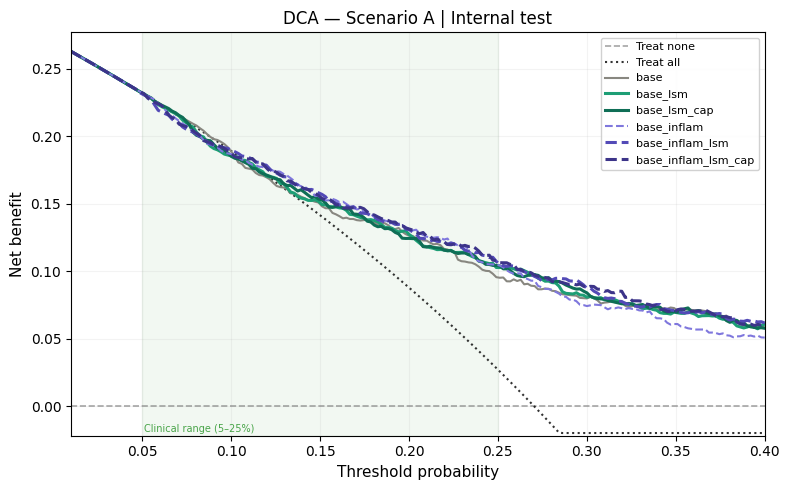

[SAVE] /home/ubuntu/eGFR25_output/dca_plots/dca_scenario_a_external.png


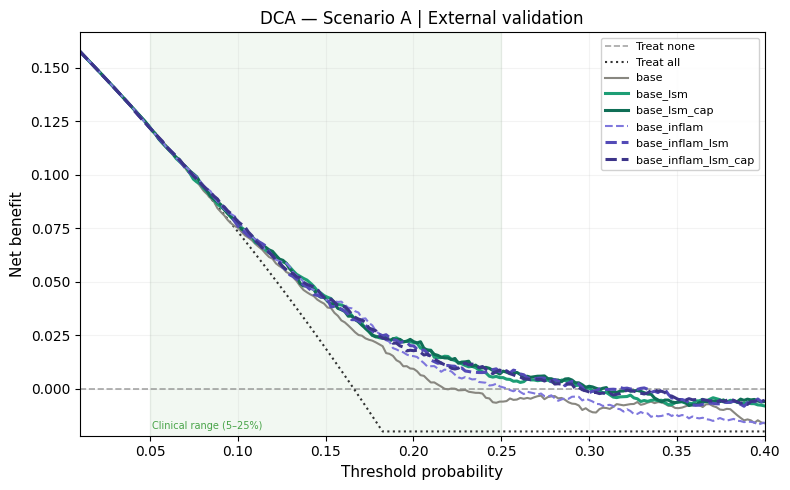

[SAVE] /home/ubuntu/eGFR25_output/dca_plots/dca_scenario_b_internal.png


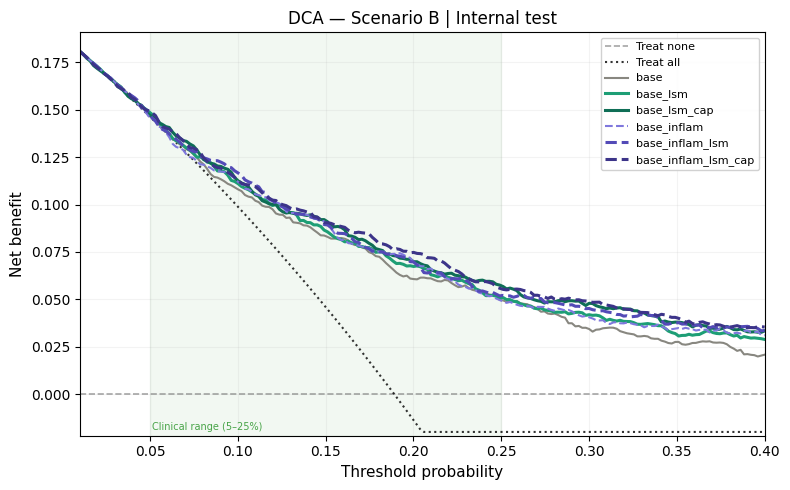

[SAVE] /home/ubuntu/eGFR25_output/dca_plots/dca_scenario_b_external.png


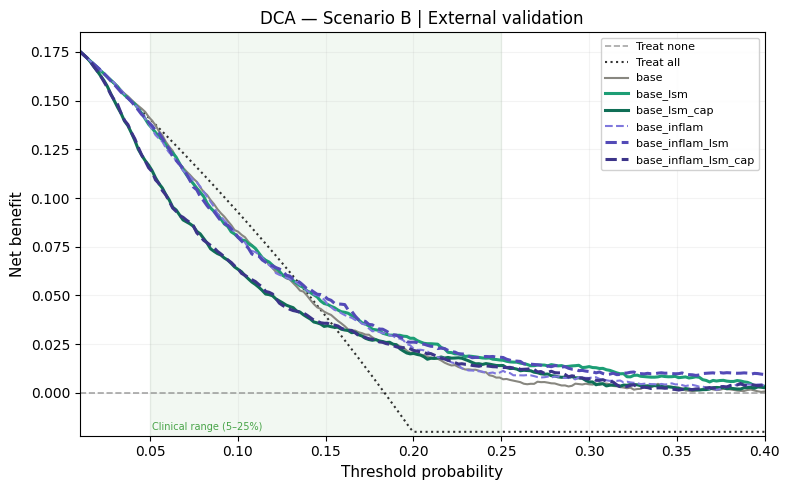

[DONE] All DCA plots saved.


In [10]:

# ── DCA helper functions ─────────────────────────────────────────────────────
def net_benefit(y_true, y_prob, thresholds):
    """Net benefit at each threshold: NB(t) = TP/n - FP/n * t/(1-t)"""
    y_true = np.asarray(y_true, dtype=int)
    y_prob = np.asarray(y_prob, dtype=float)
    n      = len(y_true)
    nb     = np.full(len(thresholds), np.nan)
    for i, t in enumerate(thresholds):
        if t >= 1.0: continue
        pred_pos = y_prob >= t
        tp = np.sum(pred_pos & (y_true == 1))
        fp = np.sum(pred_pos & (y_true == 0))
        nb[i] = tp / n - fp / n * (t / (1 - t))
    return nb


def treat_all_nb(y_true, thresholds):
    """'Treat all' reference line."""
    y_true = np.asarray(y_true, dtype=int)
    prev   = y_true.mean()
    n      = len(y_true)
    nb     = np.full(len(thresholds), np.nan)
    for i, t in enumerate(thresholds):
        if t >= 1.0: continue
        nb[i] = prev - (1 - prev) * (t / (1 - t))
    return nb


def dca_plot(pred_dict, y_true, title,
             threshold_range=(0.01, 0.40), n_thresh=200,
             clip_lower=-0.02, save_path=None):
    """
    DCA plot for all models in pred_dict.
    Block 1 models: solid lines / Block 2: dashed lines.
    Clinical range 5-25% is shaded.
    """
    thresholds = np.linspace(threshold_range[0], threshold_range[1], n_thresh)
    y_true     = np.asarray(y_true, dtype=int)

    # Visual style per model — Block1 solid, Block2 dashed
    style_map = {
        "base":                dict(ls="-",  lw=1.5, color="#888780"),
        "base_lsm":            dict(ls="-",  lw=2.2, color="#1D9E75"),
        "base_lsm_cap":        dict(ls="-",  lw=2.2, color="#0F6E56"),
        "base_inflam":         dict(ls="--", lw=1.5, color="#7F77DD"),
        "base_inflam_lsm":     dict(ls="--", lw=2.2, color="#534AB7"),
        "base_inflam_lsm_cap": dict(ls="--", lw=2.2, color="#3C3489"),
    }

    fig, ax = plt.subplots(figsize=(8, 5))

    # Reference lines
    ax.axhline(0, color="gray", ls="--", lw=1.2, label="Treat none", alpha=0.7)
    nb_all = np.clip(treat_all_nb(y_true, thresholds), clip_lower, None)
    ax.plot(thresholds, nb_all, color="black", ls=":", lw=1.5,
            label="Treat all", alpha=0.8)

    # Model curves
    for m, p in pred_dict.items():
        nb = np.clip(net_benefit(y_true, p, thresholds), clip_lower, None)
        s  = style_map.get(m, dict(ls="-", lw=1.5, color="steelblue"))
        ax.plot(thresholds, nb, label=m, **s)

    # Clinical range shading (5-25%)
    ax.axvspan(0.05, 0.25, alpha=0.05, color="green")
    ax.text(0.051, clip_lower + 0.001, "Clinical range (5–25%)",
            fontsize=7, color="green", alpha=0.7)

    ax.set_xlim(threshold_range)
    ax.set_ylim(clip_lower - 0.002, None)
    ax.set_xlabel("Threshold probability", fontsize=11)
    ax.set_ylabel("Net benefit", fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.legend(loc="upper right", fontsize=8, framealpha=0.9)
    ax.grid(True, alpha=0.15)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"[SAVE] {save_path}")
    plt.show()


# ── Execute ──────────────────────────────────────────────────────────────────
DCA_DIR = OUTDIR / "dca_plots"
DCA_DIR.mkdir(exist_ok=True)

print("=== DCA plots ===")
for scen, pred_te, y_te, pred_ex, y_ex in [
    ("Scenario_A", pred_test_A, y_test_A, pred_ext_A, y_ext_A),
    ("Scenario_B", pred_test_B, y_test,   pred_ext_B, y_ext),
]:
    dca_plot(pred_te, y_te,
             title=f"DCA — {scen.replace('_',' ')} | Internal test",
             save_path=DCA_DIR / f"dca_{scen.lower()}_internal.png")
    dca_plot(pred_ex, y_ex,
             title=f"DCA — {scen.replace('_',' ')} | External validation",
             save_path=DCA_DIR / f"dca_{scen.lower()}_external.png")

print("[DONE] All DCA plots saved.")
